# Reto 2 · Feature engineering (versión 2)

**Malackathon 2026 · Mercedes-Benz · "Clustering the Star"**

Este cuaderno prepara los datos que alimentarán el clustering. Parte de:
- **Parte 1 (`01_eda.ipynb`)**: su tabla de *propuesta de tratamiento* de nulos, su decisión de trabajar con **1 fila = 1 cliente** y las columnas que excluye.
- **Parte 2 antigua (`02_feature_engineering.ipynb`)**: se reutiliza la idea del "vehículo principal" y del pipeline, mejorados.
- **El listado de 10 features derivadas** acordado por el grupo.

Lo que pide el reto y dónde se cubre:

| Requisito del reto | Sección |
|---|---|
| Tratamiento de nulos columna a columna (según la Parte 1) | **A** |
| Agregación a 1 fila por cliente | **B** |
| Creación de features derivadas, con cálculo y columnas de origen (pandas + SQL) | **C** |
| Selección justificada de features | **D** |
| Codificación de categóricas, imputación y escalado de numéricas | **E** |
| Pipeline que encapsula todo el proceso | **E** |
| CSV final de clientes con nulos tratados y features derivadas | **F** |

```
CSV crudo (302.850 filas cliente-vehículo)
   │  A. TratamientoNulos      → cada columna según su naturaleza
   │  B. AgregacionClientes    → 1 fila por cliente + vehículo principal
   │  C. FeaturesDerivadas     → 8 features derivadas calculables
   ▼
CSV de clientes (173.456 filas, 0 nulos)  ──►  E. Preprocesado (codificación + escalado)  ──►  matriz para K-Means
```

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
CSV = next(p for p in [DATA_DIR / "datos_reto_mercedes_benz_malackathon.csv",
                       ROOT / "datos_reto_mercedes_benz_malackathon.csv"] if p.exists())

import duckdb
from sklearn import set_config
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, RobustScaler

REF_DATE = pd.Timestamp("2026-10-15")   # fecha de referencia ("hoy") para todas las antigüedades
raw = pd.read_csv(CSV, low_memory=False, dtype={"zipcode": str})
print(f"{len(raw):,} filas · {raw.shape[1]} columnas · {raw.client_id.nunique():,} clientes")

302,850 filas · 39 columnas · 173,456 clientes


---
# A. Tratamiento de nulos (a nivel fila cliente-vehículo)

Los nulos se tratan **antes** de agregar a cliente, porque muchos se pueden deducir de otras columnas del mismo vehículo.

**Principios** (el nulo de cada columna se gestiona según lo que significa esa columna):
1. Si el valor **se puede deducir** de otras columnas, se deduce, pero solo con reglas **validadas** (escondemos valores conocidos y comprobamos que los acertamos).
2. Si **no se puede deducir con fiabilidad**, no se inventa: categoría `UNKNOWN` (categóricas) o mediana de un grupo comparable **marcada con un indicador** (numéricas).
3. Si la falta es **estructural** (el dato no existe), se convierte en un indicador (`has_telemetry`) y las columnas se **eliminan** del conjunto final.

Partimos de la propuesta de la Parte 1 y la **mejoramos** en dos puntos:

| Columna | Parte 1 proponía | Aquí hacemos | Por qué |
|---|---|---|---|
| `engine_concept` | Inferir del nombre; lo no detectable → combustión | Cascada validada; lo no deducible → `UNKNOWN` | Un nulo **no** es combustión: podría ser eléctrico o híbrido |
| `fuel_type` | No usar | Se trata igual (reglas validadas + `UNKNOWN`) | El CSV final debe quedar sin nulos y con datos fiables |
| Resto | | Igual que la Parte 1, con validación | |

In [2]:
nulos = raw.isna().sum()
panorama = pd.DataFrame({"nulos": nulos, "% nulos": (nulos / len(raw) * 100).round(2)})
panorama[panorama.nulos > 0].sort_values("nulos", ascending=False)

,nulos,% nulos
trip_distance_average,185857,61.37
speed_average,182382,60.22
speed_mode,181159,59.82
speed_all_counter,181159,59.82
speed_median,181159,59.82
fuel_consumption_average,180725,59.67
trip_distance_mode,179830,59.38
trip_distance_median,179830,59.38
trip_distance_all_counter,179830,59.38
fuel_type,178745,59.02


### A.0 Herramientas de imputación

Para las categóricas deducibles usamos una **cascada**: primero reglas deterministas (validadas, ≥ 98 % de precisión);
después *tablas de consulta aprendidas de los propios datos* ("los coches con este nombre y este año, ¿qué valor tienen casi siempre?"),
aceptadas solo si el valor se repite mucho (**pureza**) en suficientes coches (**soporte**). Si nada es fiable → `UNKNOWN`.

La validación esconde el 20 % de los valores conocidos de dos formas: **al azar** (optimista) y **por nombre de coche** (todos los coches de
un mismo modelo a la vez, que simula modelos nunca vistos, el caso realista).

In [3]:
def make_key(d, cols):
    """Clave 'a|b|c'. Si falta algún componente (o vale UNKNOWN), la clave es nula y no se usa."""
    k = None
    for c in cols:
        s = d[c]
        if pd.api.types.is_float_dtype(s):
            s = s.astype("Int64")
        s = s.astype("string")
        s = s.mask(s == "UNKNOWN")
        k = s if k is None else k + "|" + s
    return k


def fit_lookup(known, key_cols, target, min_n, min_purity):
    """Valor más frecuente del target por clave, solo si soporte >= min_n y pureza >= min_purity."""
    tmp = pd.DataFrame({"k": make_key(known, key_cols), "t": known[target]}).dropna()
    cnt = tmp.groupby(["k", "t"]).size().rename("c").reset_index()
    cnt["n"] = cnt.groupby("k")["c"].transform("sum")
    top = cnt.sort_values(["k", "c"], ascending=[True, False]).drop_duplicates("k")
    top = top[(top["n"] >= min_n) & (top["c"] / top["n"] >= min_purity)]
    return dict(zip(top["k"], top["t"]))


def fit_cascade(known, target, levels):
    return [(name, cols, fit_lookup(known, cols, target, n, p)) for name, cols, n, p in levels]


def apply_cascade(d, target, rules, fitted):
    out = d[target].astype(object).copy()
    todo = out.isna()
    src = pd.Series(np.where(todo, "", "original"), index=d.index, dtype=object)
    for name, fn in rules:
        pred = fn(d); m = todo & pred.notna()
        out[m], src[m] = pred[m], name; todo = todo & ~m
    for name, cols, lk in fitted:
        pred = make_key(d, cols).map(lk).astype(object); m = todo & pred.notna()
        out[m], src[m] = pred[m], name; todo = todo & ~m
    out[todo], src[todo] = "UNKNOWN", "UNKNOWN (sin evidencia)"
    return out, src


def cascade_impute(d, target, levels, rules=()):
    return apply_cascade(d, target, rules, fit_cascade(d[d[target].notna()], target, levels))


def validate_rules(d, target, rules, min_precision=0.98):
    known = d[target].notna(); rows, kept = [], []
    for name, fn in rules:
        p = fn(d)[known]; fired = p.notna()
        prec = (p[fired] == d.loc[known, target][fired]).mean()
        rows.append({"regla": name, "filas conocidas donde se aplica": int(fired.sum()),
                     "precisión": round(prec, 4), "se usa": bool(prec >= min_precision)})
        if prec >= min_precision:
            kept.append((name, fn))
    display(pd.DataFrame(rows))
    return kept


def holdout_eval(d, target, levels, rules=(), by=None, frac=0.2, seed=0):
    rng = np.random.default_rng(seed); known = d[target].notna()
    if by is None:
        hide = known & (rng.random(len(d)) < frac)
    else:
        groups = d.loc[known, by].dropna().unique()
        hide = known & d[by].isin(set(rng.choice(groups, int(len(groups) * frac), replace=False)))
    t = d.copy(); t.loc[hide, target] = np.nan
    pred, src = cascade_impute(t, target, levels, rules)
    ok = pred[hide] == d.loc[hide, target]; dec = src[hide] != "UNKNOWN (sin evidencia)"
    return {"validación": "al azar" if by is None else f"por {by}", "filas escondidas": int(hide.sum()),
            "% decididas": round(dec.mean() * 100, 1), "% acierto cuando decide": round(ok[dec].mean() * 100, 2),
            "% quedan UNKNOWN": round((~dec).mean() * 100, 1)}


def fuentes(before_null, src):
    t = src[before_null].value_counts().rename("filas").to_frame()
    t["%"] = (t["filas"] / before_null.sum() * 100).round(1)
    return t

### A.1 `Unnamed: 0`, `date_of_first_registration` (preparación) y `vehicle_type`

- **`Unnamed: 0`**: índice exportado (0, 1, 2…). Sin nulos y sin significado → **se elimina** (Parte 1).
- **Fecha**: se convierte a fecha. Las 2 matriculaciones de 1987 son imposibles en coches conectados → **nulo** (se imputan en A.5).
  Guardamos el año original porque el motor de un coche depende del año.
- **`vehicle_type`** (0,3 %): es el nombre comercial exacto (`C 200 d`). **No es reconstruible** (la clase dice "Citan", no qué versión) → `UNKNOWN`.
  Esos coches conservan `model_series`, `model_class` y `product_group`.

In [4]:
df = raw.drop(columns="Unnamed: 0").copy()
df["date_of_first_registration"] = pd.to_datetime(df["date_of_first_registration"], errors="coerce")
absurdas = df.date_of_first_registration < "2000-01-01"
df.loc[absurdas, "date_of_first_registration"] = pd.NaT
df["reg_year"] = df.date_of_first_registration.dt.year
print(f"Fechas < 2000 pasadas a nulo: {absurdas.sum()} · nulos de fecha ahora: {df.date_of_first_registration.isna().sum():,}")

print(f"vehicle_type nulo: {df.vehicle_type.isna().sum():,} ->", df.loc[df.vehicle_type.isna(), "model_class"].value_counts().head(3).to_dict())
df["vehicle_type"] = df.vehicle_type.fillna("UNKNOWN")
df["type_prefix"] = df.vehicle_type.str.replace(r"^(?:MERCEDES-)?AMG\s+", "", regex=True).str.split().str[0]

Fechas < 2000 pasadas a nulo: 2 · nulos de fecha ahora: 4,184
vehicle_type nulo: 922 -> {'Citan': 878, 'C-Class': 32, 'S-Class': 11}


### A.2 `model_class` (1,1 %) → deducida del nombre del coche

Un `GLC 400 4MATIC` es un GLC. Dejamos que los datos digan qué clase tienen los demás coches con el **mismo nombre** (o, si no hay suficientes,
el mismo **prefijo**: `GLC`, `EQA`…). Si no hay evidencia → `UNKNOWN`.

In [5]:
MC_LEVELS = [("nombre exacto", ["vehicle_type"], 3, 0.95),
             ("prefijo del nombre", ["type_prefix"], 20, 0.90)]
display(pd.DataFrame([holdout_eval(df, "model_class", MC_LEVELS),
                      holdout_eval(df, "model_class", MC_LEVELS, by="vehicle_type")]))
was_null = df.model_class.isna()
df["model_class"], src = cascade_impute(df, "model_class", MC_LEVELS)
fuentes(was_null, src)

,validación,filas escondidas,% decididas,% acierto cuando decide,% quedan UNKNOWN
0,al azar,60096,86.3,99.85,13.7
1,por vehicle_type,68599,64.7,100.00,35.3


,filas,%
prefijo del nombre,2674,79.4
nombre exacto,695,20.6


### A.3 `engine_concept` (44 %) → cascada validada, **nunca "combustión por defecto"**

Un coche sin dato de motor **no es** necesariamente de combustión. Lo deducimos solo cuando hay evidencia:

| Orden | Nivel | Qué mira | Exigencia |
|---|---|---|---|
| 1 | Regla: nombre `EQ…` → `ELECTRIC` | Nombre | precisión ≥ 98 % comprobada |
| 2 | Regla: sufijo `e` / `de` (`C 300 e`, `GLC 300 de`) → `PLUGIN_HYBRID` | Nombre | precisión ≥ 98 % comprobada |
| 3 | Nombre + año | Motor de los demás coches con ese nombre y año | pureza 95 %, ≥ 5 coches |
| 4 | Nombre | Idem solo con el nombre | pureza 90 %, ≥ 20 coches |
| 5 | Serie + año | Idem con el número de serie | pureza 90 %, ≥ 20 coches |
| 6 | Clase + año | Idem con la clase | pureza 90 %, ≥ 20 coches |
| — | Nada fiable | `UNKNOWN` | |

El año importa: el mismo `GLC 220 d 4MATIC` es `COMBUSTION` unos años y `MILD_HYBRID` otros.

In [6]:
EQ_RE = r"^(?:MERCEDES-)?(?:AMG\s+)?EQ[A-Z]"
PHEV_RE = r"(?<=\d)\s?d?e\b"

def _name_rule(regex, value):
    return lambda d: pd.Series(np.where(d.vehicle_type.str.contains(regex, regex=True), value, None), index=d.index, dtype=object)

ENGINE_RULES = validate_rules(df, "engine_concept", [
    ("regla: nombre EQ... -> ELECTRIC", _name_rule(EQ_RE, "ELECTRIC")),
    ("regla: sufijo e/de -> PLUGIN_HYBRID", _name_rule(PHEV_RE, "PLUGIN_HYBRID"))])
ENGINE_LEVELS = [("nombre + año", ["vehicle_type", "reg_year"], 5, 0.95),
                 ("nombre", ["vehicle_type"], 20, 0.90),
                 ("serie + año", ["model_series", "reg_year"], 20, 0.90),
                 ("clase + año", ["model_class", "reg_year"], 20, 0.90)]
pd.DataFrame([holdout_eval(df, "engine_concept", ENGINE_LEVELS, ENGINE_RULES),
              holdout_eval(df, "engine_concept", ENGINE_LEVELS, ENGINE_RULES, by="vehicle_type")])

,regla,filas conocidas donde se aplica,precisión,se usa
0,regla: nombre EQ... -> ELECTRIC,15764,1.0000,True
1,regla: sufijo e/de -> PLUGIN_HYBRID,19379,0.9905,True


,validación,filas escondidas,% decididas,% acierto cuando decide,% quedan UNKNOWN
0,al azar,34025,98.8,99.86,1.2
1,por vehicle_type,39072,66.6,100.00,33.4


,filas,%
nombre,33543,25.0
UNKNOWN (sin evidencia),33364,24.8
serie + año,25651,19.1
nombre + año,25510,19.0
regla: sufijo e/de -> PLUGIN_HYBRID,7924,5.9
regla: nombre EQ... -> ELECTRIC,7114,5.3
clase + año,1284,1.0


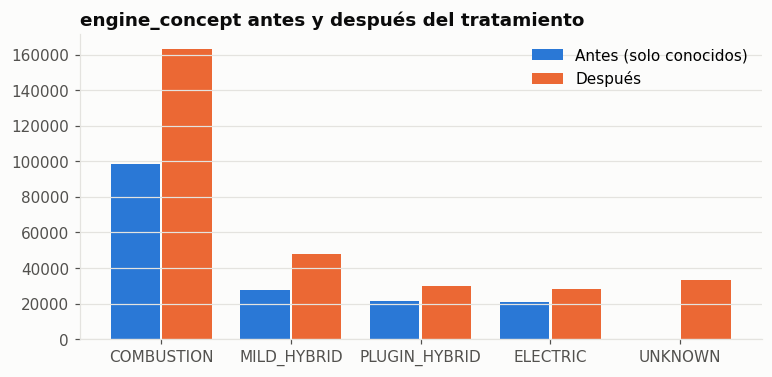

In [7]:
engine_before = df.engine_concept.copy()
df["engine_concept_imputed"] = df.engine_concept.isna()
df["engine_concept"], src = cascade_impute(df, "engine_concept", ENGINE_LEVELS, ENGINE_RULES)
display(fuentes(df.engine_concept_imputed, src))

orden = ["COMBUSTION", "MILD_HYBRID", "PLUGIN_HYBRID", "ELECTRIC", "UNKNOWN"]
fig, ax = plt.subplots(figsize=(8, 3.6)); x = np.arange(len(orden))
ax.bar(x - 0.2, engine_before.value_counts().reindex(orden).fillna(0), 0.38, color=ps.SERIES[0], label="Antes (solo conocidos)")
ax.bar(x + 0.2, df.engine_concept.value_counts().reindex(orden), 0.38, color=ps.SERIES[1], label="Después")
ax.set_xticks(x, orden); ax.set_title("engine_concept antes y después del tratamiento"); ax.legend()
fig.savefig(FIG_DIR / "02b_engine_antes_despues.png"); plt.show()

En las dos validaciones, **cuando la cascada decide, acierta**. Los coches sin evidencia quedan como `UNKNOWN`, que en el modelo será
una categoría más (one-hot), no una combustión inventada.

### A.4 `fuel_type` (59 %) → reglas validadas usando el motor ya tratado

- Un eléctrico siempre es `ELECTRIC`.
- Un nombre diésel (`220 d`, `300 de`, `CDI`) con motor de combustión o mild-hybrid → `DIESEL`; con híbrido enchufable → `DIESEL,ELECTRIC`.
- Mismo nombre + mismo motor ya visto con combustible conocido → ese combustible.
- **No** usamos niveles más generales (serie, clase): en modelos no diésel el nombre no distingue `PETROL` de `PETROL_PLUS`, y probándolos
  con modelos nunca vistos fallaban más de la mitad de las veces. Lo no deducible → `UNKNOWN`.

In [8]:
DIESEL_RE = r"(?<=\d)\s?d(?:e)?\b|\bCDI\b|\bBlueTEC\b"

def add_diesel_flag(d):
    d["diesel_flag"] = np.where(d.vehicle_type.str.contains(DIESEL_RE, regex=True), "D", "N")
    d.loc[d.vehicle_type == "UNKNOWN", "diesel_flag"] = "UNKNOWN"
    return d

def _fuel_rule(diesel, engines, value):
    return lambda d: pd.Series(np.where((d.diesel_flag == diesel) & d.engine_concept.isin(engines), value, None), index=d.index, dtype=object)

df = add_diesel_flag(df)
FUEL_RULES = validate_rules(df, "fuel_type", [
    ("regla: motor ELECTRIC -> ELECTRIC",
     lambda d: pd.Series(np.where(d.engine_concept == "ELECTRIC", "ELECTRIC", None), index=d.index, dtype=object)),
    ("regla: nombre diésel + combustión/MHEV -> DIESEL", _fuel_rule("D", ["COMBUSTION", "MILD_HYBRID"], "DIESEL")),
    ("regla: nombre diésel + PHEV -> DIESEL,ELECTRIC", _fuel_rule("D", ["PLUGIN_HYBRID"], "DIESEL,ELECTRIC"))])
FUEL_LEVELS = [("nombre + motor", ["vehicle_type", "engine_concept"], 5, 0.95)]
display(pd.DataFrame([holdout_eval(df, "fuel_type", FUEL_LEVELS, FUEL_RULES),
                      holdout_eval(df, "fuel_type", FUEL_LEVELS, FUEL_RULES, by="vehicle_type")]))
was_null = df.fuel_type.isna()
df["fuel_type"], src = cascade_impute(df, "fuel_type", FUEL_LEVELS, FUEL_RULES)
fuentes(was_null, src)

,regla,filas conocidas donde se aplica,precisión,se usa
0,regla: motor ELECTRIC -> ELECTRIC,20944,1.0,True
1,regla: nombre diésel + combustión/MHEV -> DIESEL,31676,1.0,True
2,"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",8604,1.0,True


,validación,filas escondidas,% decididas,% acierto cuando decide,% quedan UNKNOWN
0,al azar,25010,96.3,100.0,3.7
1,por vehicle_type,25880,47.9,100.0,52.1


,filas,%
UNKNOWN (sin evidencia),87989,49.2
regla: nombre diésel + combustión/MHEV -> DIESEL,48363,27.1
nombre + motor,32126,18.0
regla: motor ELECTRIC -> ELECTRIC,7114,4.0
"regla: nombre diésel + PHEV -> DIESEL,ELECTRIC",3153,1.8


### A.5 `date_of_first_registration` (1,4 %) → mediana de la serie del modelo

La fecha exacta no se puede deducir, pero cada serie **se vende en una ventana de años limitada**. Imputamos la mediana de fecha de los
coches de la **misma serie** y lo validamos frente al relleno ingenuo (mediana global). Se marca con `registration_date_imputed`
porque de esta fecha sale la feature principal del reto (antigüedad del vehículo).

In [9]:
epoch = pd.Timestamp("2000-01-01")
days = (df.date_of_first_registration - epoch).dt.days
rng = np.random.default_rng(0); known = days.notna(); hide = known & (rng.random(len(df)) < 0.2)
train = df[known & ~hide].assign(days=days)
pred = df.loc[hide, "model_series"].map(train.groupby("model_series").days.median()).fillna(train.days.median())
err_serie = ((pred - days[hide]).abs() / 365.25).median()
err_global = ((train.days.median() - days[hide]).abs() / 365.25).median()
print(f"Error mediano al imputar · mediana de la serie: {err_serie:.2f} años · mediana global: {err_global:.2f} años")

df["registration_date_imputed"] = df.date_of_first_registration.isna()
days = days.fillna(df.assign(days=days).groupby("model_series").days.transform("median")).fillna(days.median())
df["date_of_first_registration"] = epoch + pd.to_timedelta(days.round(), unit="D")
print(f"Fechas imputadas: {df.registration_date_imputed.sum():,}")

Error mediano al imputar · mediana de la serie: 1.26 años · mediana global: 2.25 años
Fechas imputadas: 4,184


### A.6 `gender_derived` (11 %) → `UNKNOWN`, sin imputar

Es un dato **inferido**, no declarado, y sus nulos **no son aleatorios**:

In [10]:
g = raw.gender_derived.isna()
display(pd.concat({"según rol": g.groupby(raw.role).mean(), "según edad": g.groupby(raw.age_range).mean()}).mul(100).round(1).to_frame("% nulo"))
df["gender_derived"] = df.gender_derived.fillna("UNKNOWN")
print("Género conocido:", raw.gender_derived.value_counts(normalize=True).round(2).to_dict())

% nulo
según rol  DRIVER        4.1
           LEGACY       11.9
           OWNER         9.2
           TEMP_USER    38.1
           USER         36.2
según edad 25-34        11.9
           35-44         8.7
           45-54         7.1
           55-64         5.6
           65+          21.1
           <25          34.3

Género conocido: {'male': 0.83, 'female': 0.17}


Falta mucho más en usuarios secundarios (`USER`, `TEMP_USER`) y en los extremos de edad: **que falte ya es información**.
Rellenar con la moda (hombre) atribuiría un género sin base a miles de personas. Queda como categoría `UNKNOWN`. Además, como dice la Parte 1,
**no entra en el modelo** (riesgo de sesgo).

### A.7 `months_as_mb_customer` (4 filas) → mediana de clientes comparables

Son 2 clientes, ambos con **0 vehículos conectados**. Los clientes en esa situación tienen una antigüedad mediana distinta de la global,
así que imputamos la mediana de su grupo (mismo nº de vehículos conectados).

In [11]:
grp = df.groupby("currently_connected_vehicles").months_as_mb_customer
print("Mediana grupo 0 vehículos:", grp.median().get(0), "· mediana global:", df.months_as_mb_customer.median())
df["months_as_mb_customer"] = df.months_as_mb_customer.fillna(grp.transform("median")).fillna(df.months_as_mb_customer.median())

Mediana grupo 0 vehículos: 26.0 · mediana global: 39.0


### A.8 Zona: `zipcode` y variables socioeconómicas (5-6 %)

- Faltan **todas a la vez** (cliente sin código postal o código postal no casado con la tabla de zonas): no hay ninguna que se deduzca de otra.
- `population = 0` (73 filas) son zonas sin datos → **nulo** (Parte 1).
- Austria y Suiza son económicamente muy distintas y el país **nunca** es nulo → **mediana del país**.
- `purchasing_power_millions_eur` cumple exactamente `= pp_por_habitante × población / 1e6` → **se recalcula** en vez de imputarse por separado.
- `zipcode` es un identificador → `UNKNOWN` (y, como dice la Parte 1, no entra en el modelo).
- Se marca con `socio_imputed`.

In [12]:
ZONE_COLS = ["purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur", "population", "number_of_households"]
ok = raw.dropna(subset=ZONE_COLS + ["purchasing_power_millions_eur"])
rel = (ok.purchasing_power_per_inhabitant_eur * ok.population / 1e6 / ok.purchasing_power_millions_eur - 1).abs().median()
print(f"Error relativo mediano de la identidad millones = pp_hab × población / 1e6: {rel:.1e}")

df.loc[df.population == 0, ["population", "number_of_households"]] = np.nan
df["socio_imputed"] = df.purchasing_power_per_household_eur.isna()
zone_med = df.groupby("country_code")[ZONE_COLS].median()
display(zone_med.round(0))
for c in ZONE_COLS:
    df[c] = df[c].fillna(df.country_code.map(zone_med[c]))
df.loc[df.socio_imputed, "purchasing_power_millions_eur"] = (df.purchasing_power_per_inhabitant_eur * df.population / 1e6)[df.socio_imputed]
df["zipcode"] = df.zipcode.fillna("UNKNOWN")
print(f"Filas con datos de zona imputados: {df.socio_imputed.sum():,}")

Error relativo mediano de la identidad millones = pp_hab × población / 1e6: 5.7e-07


,purchasing_power_per_inhabitant_eur,purchasing_power_per_household_eur,population,number_of_households
country_code,,,,
AT,30343.0,68008.0,9407.0,4227.0
CH,51423.0,115775.0,6600.0,2861.0


Filas con datos de zona imputados: 19,087


### A.9 Telemetría (~60 %) → indicador `has_telemetry` y **eliminación** de las métricas

`trip_*`, `speed_*`, `operating_hours_total`, `fuel_consumption_average`: el nulo significa "este coche **no envía** datos de conducción".
Imputar el 60 % crearía una masa artificial de "conductores medianos" que K-Means convertiría en un cluster (Parte 1).

**Decisión (acordada por el grupo):** se convierte en el indicador **`has_telemetry`** (ver C.7) y las métricas **no pasan** al CSV final ni al modelo.
Lo mismo con `trip_distance_mode`, `speed_mode` (texto con varias modas) y `*_all_counter` (contadores técnicos), excluidas en la Parte 1.

Calculamos la presencia **por bloque** antes de descartar las métricas:

In [13]:
TEL_BLOCKS = {"trip": "trip_distance_median", "speed": "speed_median", "hours": "operating_hours_total", "consumption": "fuel_consumption_average"}
for k, c in TEL_BLOCKS.items():
    df[f"has_{k}_data"] = df[c].notna()
df["has_telemetry_row"] = df[[f"has_{k}_data" for k in TEL_BLOCKS]].any(axis=1)
pd.concat({"% con dato, por motor": df.groupby("engine_concept")[[f"has_{k}_data" for k in TEL_BLOCKS] + ["has_telemetry_row"]].mean()}).mul(100).round(1)

has_trip_data  has_speed_data  has_hours_data  has_consumption_data  has_telemetry_row
                      engine_concept                                                                                        
% con dato, por motor COMBUSTION               38.1            44.3            47.7                  46.2               49.9
                      ELECTRIC                 46.3             0.0             0.0                   0.0               46.3
                      MILD_HYBRID              46.7            48.0            49.6                  48.3               50.3
                      PLUGIN_HYBRID            51.8            53.4            53.0                  42.6               54.1
                      UNKNOWN                  29.4            30.7            32.6                  32.0               33.4

Los **eléctricos nunca** tienen consumo de combustible (no consumen combustible), aunque sí envían otros datos. Esto importa para C.7.

### A.10 Resumen: qué se ha hecho con cada columna

In [14]:
TRAT = {
 "Unnamed: 0": ("Eliminada", "Índice exportado sin significado (Parte 1)."),
 "client_id": ("Sin nulos · clave", "Clave de agregación; no es feature."),
 "vehicle_id": ("Sin nulos · clave", "Sirve para contar vehículos por cliente; no es feature."),
 "age_range": ("Sin nulos", "Se codifica como ordinal en el pipeline."),
 "gender_derived": ("UNKNOWN", "Nulo no aleatorio y dato inferido; no se imputa y no entra en el modelo."),
 "model_series": ("Sin nulos", "Pista para deducir otras columnas; excluida del modelo (Parte 1)."),
 "vehicle_type": ("UNKNOWN", "Nombre comercial no reconstruible; excluida del modelo (Parte 1)."),
 "model_class": ("Deducida (validada)", "Del nombre del coche; sin evidencia -> UNKNOWN."),
 "product_group": ("Sin nulos", "Base de main_is_van."),
 "engine_concept": ("Deducida (validada)", "Cascada reglas/nombre/año/serie/clase; sin evidencia -> UNKNOWN (no combustión)."),
 "country_code": ("Sin nulos", "Grupo para imputar la zona; base de itvs_passed_count."),
 "fuel_type": ("Deducida (validada)", "Reglas por motor y nombre diésel; sin evidencia -> UNKNOWN."),
 "date_of_first_registration": ("Mediana de la serie", "Fechas < 2000 -> nulo; marca registration_date_imputed."),
 "is_current_vehicle": ("Sin nulos", "Elige el vehículo principal."),
 "role": ("Sin nulos", "Se conserva el del vehículo principal."),
 "role_type": ("Sin nulos", "Base de is_b2b."),
 "months_as_mb_customer": ("Mediana de grupo", "4 filas: mediana del grupo con igual nº de vehículos conectados."),
 "currently_connected_vehicles": ("Sin nulos", "Base de digital_engagement_index."),
 "finance_leasing_status": ("Sin nulos", "One-hot en el pipeline."),
 "workshop_visits_warranty_goodwill": ("Sin nulos", "Base de warranty_visit_frequency."),
 "consent_phone_communication_channel": ("Sin nulos", "Se conserva en el CSV."),
 "consent_epost_communication_channel": ("Sin nulos", "Base de digital_engagement_index."),
 "consent_post_communication_channel": ("Sin nulos", "Se conserva en el CSV."),
 "purchasing_power_per_inhabitant_eur": ("Mediana del país", "Marca socio_imputed."),
 "purchasing_power_per_household_eur": ("Mediana del país", "Marca socio_imputed."),
 "population": ("Mediana del país", "Ceros -> nulo; marca socio_imputed."),
 "zipcode": ("UNKNOWN", "Identificador geográfico; excluido del CSV final y del modelo (Parte 1)."),
 "trip_distance_average": ("Eliminada -> has_telemetry", "Falta estructural; no se imputa."),
 "trip_distance_mode": ("Eliminada", "Texto multivalor (Parte 1)."),
 "trip_distance_median": ("Eliminada -> has_telemetry", "Falta estructural; no se imputa."),
 "trip_distance_all_counter": ("Eliminada", "Contador técnico (Parte 1)."),
 "operating_hours_total": ("Eliminada -> has_telemetry", "Falta estructural; no se imputa."),
 "fuel_consumption_average": ("Eliminada -> has_telemetry", "Falta estructural; en eléctricos no existe."),
 "speed_average": ("Eliminada -> has_telemetry", "Falta estructural; no se imputa."),
 "speed_mode": ("Eliminada", "Texto multivalor (Parte 1)."),
 "speed_median": ("Eliminada -> has_telemetry", "Falta estructural; no se imputa."),
 "speed_all_counter": ("Eliminada", "Contador técnico (Parte 1)."),
 "number_of_households": ("Mediana del país", "Ceros -> nulo; marca socio_imputed."),
 "purchasing_power_millions_eur": ("Recalculada", "= pp por habitante × población / 1e6."),
}
assert set(TRAT) == set(raw.columns)
resumen_nulos = pd.DataFrame({"nulos antes": raw.isna().sum(), "% antes": (raw.isna().mean() * 100).round(2),
                              "tratamiento": {c: v[0] for c, v in TRAT.items()}, "detalle": {c: v[1] for c, v in TRAT.items()}})
resumen_nulos.to_csv(ROOT / "reports" / "fe2_tratamiento_nulos.csv", index_label="columna")
pd.set_option("display.max_colwidth", 120)
resumen_nulos

,nulos antes,% antes,tratamiento,detalle
Unnamed: 0,0,0.00,Eliminada,Índice exportado sin significado (Parte 1).
client_id,0,0.00,Sin nulos · clave,Clave de agregación; no es feature.
vehicle_id,0,0.00,Sin nulos · clave,Sirve para contar vehículos por cliente; no es feature.
age_range,0,0.00,Sin nulos,Se codifica como ordinal en el pipeline.
gender_derived,33923,11.20,UNKNOWN,Nulo no aleatorio y dato inferido; no se imputa y no entra en el modelo.
model_series,0,0.00,Sin nulos,Pista para deducir otras columnas; excluida del modelo (Parte 1).
vehicle_type,922,0.30,UNKNOWN,Nombre comercial no reconstruible; excluida del modelo (Parte 1).
model_class,3369,1.11,Deducida (validada),Del nombre del coche; sin evidencia -> UNKNOWN.
product_group,0,0.00,Sin nulos,Base de main_is_van.
engine_concept,134390,44.38,Deducida (validada),Cascada reglas/nombre/año/serie/clase; sin evidencia -> UNKNOWN (no combustión).


---
# B. Agregación a 1 fila por cliente

Como decidió la Parte 1, se segmentan **clientes**, no coches. Cada cliente se resume así:

- **Atributos del cliente** (edad, antigüedad, financiación, consentimientos, zona): son constantes en todas sus filas → se copian.
- **Vehículo principal**: el **vehículo actual** matriculado más recientemente; si no tiene ninguno actual, el más reciente. Desempate por `vehicle_id`.
  De él salen las columnas `main_*`.
- **Agregados del historial**: nº de vehículos distintos, visitas a taller totales, si alguna relación es B2B, si algún vehículo tiene telemetría.

En SQL (el mismo criterio se ejecuta en C.11 para comprobarlo):
```sql
WITH ranked AS (
  SELECT *, ROW_NUMBER() OVER (PARTITION BY client_id
            ORDER BY is_current_vehicle DESC, date_of_first_registration DESC, vehicle_id) AS rn
  FROM filas_limpias)
SELECT * FROM ranked WHERE rn = 1;          -- vehículo principal de cada cliente
```

In [15]:
CLIENT_COLS = ["age_range", "gender_derived", "country_code", "months_as_mb_customer", "currently_connected_vehicles",
               "finance_leasing_status", "consent_phone_communication_channel", "consent_epost_communication_channel",
               "consent_post_communication_channel", "purchasing_power_per_inhabitant_eur", "purchasing_power_per_household_eur",
               "population", "number_of_households", "purchasing_power_millions_eur", "socio_imputed"]
MAIN_COLS = {"vehicle_type": "main_vehicle_type", "model_class": "main_model_class", "product_group": "main_product_group",
             "engine_concept": "main_engine_concept", "fuel_type": "main_fuel_type", "role": "main_role",
             "date_of_first_registration": "main_date_of_first_registration",
             "registration_date_imputed": "main_registration_date_imputed", "engine_concept_imputed": "main_engine_concept_imputed"}

def agregar_clientes(rows):
    r = rows.sort_values(["client_id", "is_current_vehicle", "date_of_first_registration", "vehicle_id"],
                         ascending=[True, False, False, True])
    main = r.groupby("client_id", sort=True).head(1).set_index("client_id")
    cli = main[CLIENT_COLS].join(main[list(MAIN_COLS)].rename(columns=MAIN_COLS))
    agg = (r.assign(_b2b=r.role_type.eq("B2B"))
            .groupby("client_id")
            .agg(n_vehicles_history=("vehicle_id", "nunique"),
                 workshop_visits_total=("workshop_visits_warranty_goodwill", "sum"),
                 is_b2b=("_b2b", "max"),
                 has_telemetry=("has_telemetry_row", "max")))
    return cli.join(agg)

clientes = agregar_clientes(df)
print(f"Tabla de clientes: {clientes.shape[0]:,} filas · {clientes.shape[1]} columnas")
print(f"% de clientes cuyo vehículo principal es un vehículo actual: {(clientes.currently_connected_vehicles > 0).mean():.1%}")
clientes.head(3).T

Tabla de clientes: 173,456 filas · 28 columnas
% de clientes cuyo vehículo principal es un vehículo actual: 89.6%


client_id,0000eb1785b60456d8ca6059563d61ad9ec480b63d69f616478bc9eb50510d33,000144e39c02702f821f69beeb7036f40cf8505051050f38ea776337ef9b6f3c,00017f3423e3110fffd0e920f7bc09af8be9e76afd000486fba5946417888eb5
age_range,55-64,35-44,45-54
gender_derived,male,female,male
country_code,AT,AT,AT
months_as_mb_customer,46.0,36.0,3.0
currently_connected_vehicles,1,1,1
finance_leasing_status,never_active,never_active,active_FL_only
consent_phone_communication_channel,True,False,True
consent_epost_communication_channel,True,True,True
consent_post_communication_channel,True,False,True
purchasing_power_per_inhabitant_eur,31455.75,31518.15,31943.22


---
# C. Features derivadas

Para cada una: **qué mide**, **columnas de origen**, **cálculo** (fórmula, pandas y SQL) y **por qué es útil**.
Todas parten de columnas ya tratadas en la sección A, y **ninguna depende de columnas excluidas** en la Parte 1 (ni de la telemetría con nulos).

Al revisar el listado del grupo contra los datos reales encontramos **cuatro ajustes necesarios** y **dos features que no se pueden calcular**.
Se explican en cada apartado:

| # | Feature | Estado |
|---|---|---|
| 1 | `main_vehicle_age_years` | ✅ Como estaba definida |
| 2 | `tenure_years` | ✅ Como estaba definida |
| 3 | `itvs_passed_count` | ✅ **Ajustada**: calendario de inspección real de Austria y Suiza |
| 4 | `warranty_visit_frequency` | ✅ **Ajustada**: se divide por vehículos del historial (como dice la definición; el código de ejemplo usaba vehículos conectados) |
| 5 | `days_since_last_workshop_visit` | ❌ **No calculable**: el dataset no tiene fechas de visitas al taller |
| 6 | `post_warranty_retention_flag` | ❌ **No calculable**: solo hay visitas *en garantía* y sin fecha |
| 7 | `has_telemetry` | ✅ **Ajustada**: cualquier dato de telemetría (solo con el consumo, los eléctricos salían todos sin telemetría) |
| 8 | `urban_density_classification` | ✅ Calculada como ratio; **se analiza qué mide de verdad** |
| 9 | `digital_engagement_index` | ✅ Como estaba definida |
| 10 | `main_is_van` | ✅ **Ajustada**: en los datos las furgonetas son `product_group = 'T'` (no existe `'V'`) |

### C.1 `main_vehicle_age_years` · Antigüedad del vehículo principal

- **Qué mide:** años desde la primera matriculación del vehículo principal.
- **Columnas de origen:** `date_of_first_registration` (tratada en A.5) del vehículo principal.
- **Cálculo:** $\text{main\_vehicle\_age\_years} = \dfrac{\text{2026-10-15} - \text{date\_of\_first\_registration}}{365{,}25}$
- **SQL:** `(DATE '2026-10-15' - date_of_first_registration) / 365.25`
- **Por qué es útil:** detecta la **ventana de renovación** (coches de más de 4-5 años) para ofertas de recompra.
- No hace falta `fillna` como en el código de ejemplo: la fecha ya no tiene nulos (A.5) y las imputadas quedan marcadas en `main_registration_date_imputed`.

In [16]:
def f_main_vehicle_age_years(c):
    return (REF_DATE - c["main_date_of_first_registration"]).dt.days / 365.25

clientes["main_vehicle_age_years"] = f_main_vehicle_age_years(clientes)
clientes.main_vehicle_age_years.describe().round(2)

count    173456.00
mean          4.65
std           3.05
min           0.04
25%           2.21
50%           4.24
75%           6.69
max          26.33
Name: main_vehicle_age_years, dtype: float64

### C.2 `tenure_years` · Antigüedad como cliente

- **Qué mide:** años que lleva el cliente vinculado a la marca (desde su primera conexión a un coche).
- **Columnas de origen:** `months_as_mb_customer` (4 nulos tratados en A.7).
- **Cálculo:** $\text{tenure\_years} = \text{months\_as\_mb\_customer} / 12$ · **SQL:** `months_as_mb_customer / 12.0`
- **Por qué es útil:** mide la **lealtad** y el momento del ciclo de vida del cliente (recién llegado vs. veterano).

In [17]:
def f_tenure_years(c):
    return c["months_as_mb_customer"] / 12.0

clientes["tenure_years"] = f_tenure_years(clientes)
display(clientes.tenure_years.describe().round(2).to_frame().T)
m = raw.drop_duplicates("client_id").months_as_mb_customer.value_counts().sort_index()
print("Clientes por meses como cliente (30-42):", m.loc[30:42].astype(int).to_dict())

,count,mean,std,min,25%,50%,75%,max
tenure_years,173456.0,2.82,1.73,0.0,1.5,3.0,3.92,10.0


Clientes por meses como cliente (30-42): {30.0: 2543, 31.0: 2174, 32.0: 2056, 33.0: 2069, 34.0: 2174, 35.0: 2619, 36.0: 21179, 37.0: 2770, 38.0: 2739, 39.0: 2298, 40.0: 2212, 41.0: 2242, 42.0: 2508}


**Anomalía detectada:** 21.179 clientes (≈12 %) tienen **exactamente 36 meses**, frente a ~2.200 en los meses vecinos. No es un nulo,
pero parece un **valor por defecto** del sistema de origen (p. ej. clientes cargados en una migración hace 3 años). No lo modificamos porque no
sabemos su valor real, pero conviene **confirmarlo con Mercedes-Benz**: si es un valor por defecto, esos clientes formarían una acumulación
artificial en `tenure_years`.

### C.3 `itvs_passed_count` · Inspecciones técnicas obligatorias superadas

- **Qué mide:** cuántas inspecciones periódicas obligatorias ha tenido que pasar el vehículo principal según su antigüedad.
- **Columnas de origen:** `main_vehicle_age_years` (C.1) y `country_code`.
- **Ajuste respecto al listado:** la fórmula propuesta (primera a los 4 años y luego cada 2) es el calendario de la **ITV española**.
  Nuestros clientes son de **Austria y Suiza**, que tienen calendarios distintos, así que aplicamos el de cada país:

| País | Inspección | Calendario para turismos | Fórmula (edad = *a* años) |
|---|---|---|---|
| Austria | *§57a-Begutachtung* ("Pickerl") | a los 3 años, a los 5 y después cada año ("3-2-1") | 0 si *a* < 3 · 1 si 3 ≤ *a* < 5 · 2 + ⌊*a* − 5⌋ si *a* ≥ 5 |
| Suiza | *MFK / Motorfahrzeugkontrolle* | a los 5 años, a los 8 y después cada 2 años ("5-3-2") | 0 si *a* < 5 · 1 si 5 ≤ *a* < 8 · 2 + ⌊(*a* − 8)/2⌋ si *a* ≥ 8 |
| *(listado original)* | *ITV España* | *4 años y después cada 2* | *máx(0, ⌊(a − 4)/2⌋ + 1)* |

> Calendarios generales para turismos. Conviene que el grupo los confirme con la normativa vigente si se usan en la presentación.

- **SQL:**
```sql
CASE WHEN country_code = 'AT' THEN CASE WHEN age < 3 THEN 0 WHEN age < 5 THEN 1 ELSE 2 + FLOOR(age - 5) END
     ELSE                          CASE WHEN age < 5 THEN 0 WHEN age < 8 THEN 1 ELSE 2 + FLOOR((age - 8) / 2) END
END
```
- **Por qué es útil:** separa los coches nuevos de los **maduros que ya pasan por posventa fuera de garantía**, y lo hace con el calendario
  que realmente vive el cliente (un austriaco empieza a pasar inspecciones 2 años antes que un suizo).

In [18]:
def f_itvs_passed_count(c):
    a = c["main_vehicle_age_years"].to_numpy()
    at = np.where(a < 3, 0, np.where(a < 5, 1, 2 + np.floor(a - 5)))
    ch = np.where(a < 5, 0, np.where(a < 8, 1, 2 + np.floor((a - 8) / 2)))
    return pd.Series(np.where(c["country_code"].to_numpy() == "AT", at, ch), index=c.index).astype(int)

def itvs_formula_listado(c):          # solo para comparar
    a = c["main_vehicle_age_years"]
    return np.where(a >= 4, np.floor((a - 4) / 2) + 1, 0).astype(int)

clientes["itvs_passed_count"] = f_itvs_passed_count(clientes)
comp = pd.crosstab(clientes.country_code, clientes.itvs_passed_count.clip(upper=5))
comp.columns = [str(c) if c < 5 else "5+" for c in comp.columns]
print("Calendario del país (filas = país, columnas = nº de inspecciones):"); display(comp)
print(f"Clientes en los que el calendario del país y la fórmula española difieren: "
      f"{(clientes.itvs_passed_count != itvs_formula_listado(clientes)).mean():.1%}")

Calendario del país (filas = país, columnas = nº de inspecciones):


,0,1,2,3,4,5+
country_code,,,,,,
AT,22316,12962,6150,5192,4295,7778
CH,64975,33832,9916,4062,1116,862


Clientes en los que el calendario del país y la fórmula española difieren: 45.7%


### C.4 `warranty_visit_frequency` · Frecuencia de visitas en garantía

- **Qué mide:** cuántas visitas al taller oficial en garantía acumula el cliente **por cada vehículo** que ha tenido.
- **Columnas de origen:** `workshop_visits_warranty_goodwill` (por vehículo) y `vehicle_id` (para contar vehículos distintos).
- **Cálculo:** $\text{warranty\_visit\_frequency} = \dfrac{\sum \text{workshop\_visits\_warranty\_goodwill}}{\text{n\_vehicles\_history}}$
- **SQL:** `SUM(workshop_visits_warranty_goodwill) * 1.0 / COUNT(DISTINCT vehicle_id)` agrupando por `client_id`.
- **Ajuste:** el código de ejemplo dividía por `currently_connected_vehicles`. Pero las visitas se acumulan en **todos** los vehículos del historial
  (también los que ya no tiene), y además hay clientes con 0 vehículos conectados. Seguimos la definición escrita: **vehículos del historial**.
- **Por qué es útil:** identifica clientes con mucha demanda de posventa (o incidencias recurrentes) → **planes de mantenimiento**.

In [19]:
def f_warranty_visit_frequency(c):
    return c["workshop_visits_total"] / c["n_vehicles_history"]

clientes["warranty_visit_frequency"] = f_warranty_visit_frequency(clientes)
mal = clientes.workshop_visits_total / clientes.currently_connected_vehicles.clip(lower=1)
print(f"Clientes con 0 vehículos conectados: {(clientes.currently_connected_vehicles == 0).sum():,} "
      f"(con el código de ejemplo se les dividiría por 1 aunque hayan tenido varios coches)")
clientes.warranty_visit_frequency.describe().round(2)

Clientes con 0 vehículos conectados: 18,047 (con el código de ejemplo se les dividiría por 1 aunque hayan tenido varios coches)


count    173456.00
mean          2.09
std           2.35
min           0.00
25%           0.00
50%           1.50
75%           3.00
max          36.33
Name: warranty_visit_frequency, dtype: float64

### C.5 `days_since_last_workshop_visit` · ❌ No calculable

- **Qué mediría:** días desde la última visita al taller.
- **Columnas que haría falta:** la **fecha** de cada visita al taller.
- **Problema:** el dataset **no tiene ninguna fecha de visita**. La única columna de taller es `workshop_visits_warranty_goodwill`, que es un
  **contador** sin fecha. La única fecha del dataset es la de matriculación, que no dice nada de cuándo fue el cliente al taller.
- **Decisión:** **no se crea**. Cualquier valor sería inventado. Si Mercedes-Benz aportara el histórico de órdenes de taller, el cálculo sería:
```sql
SELECT client_id, DATE '2026-10-15' - MAX(visit_date) AS days_since_last_workshop_visit
FROM ordenes_taller GROUP BY client_id;     -- tabla que NO tenemos
```

In [20]:
print("Columnas con fechas en el dataset:", [c for c in raw.columns if "date" in c])
print("Columnas de taller:", [c for c in raw.columns if "workshop" in c],
      "-> tipo:", raw.workshop_visits_warranty_goodwill.dtype, "(contador, sin fecha)")

Columnas con fechas en el dataset: ['date_of_first_registration']
Columnas de taller: ['workshop_visits_warranty_goodwill'] -> tipo: int64 (contador, sin fecha)


### C.6 `post_warranty_retention_flag` · ❌ No calculable

- **Qué mediría:** si el cliente **sigue yendo al taller oficial después** de que acabe la garantía (coche de más de 3 años + visita reciente).
- **Problema:** necesita visitas **posteriores a la garantía** y **recientes**. Pero `workshop_visits_warranty_goodwill` cuenta **solo visitas en garantía**
  y sin fecha: por definición no puede reflejar visitas fuera de garantía, ni si son recientes.
- **Por qué no usamos una aproximación:** "coche > 3 años y alguna visita en garantía" mediría que el cliente **usó el taller durante la garantía**,
  no que **siga** yendo después. Llamarlo "retención post-garantía" sería engañoso para marketing.
- **Decisión:** **no se crea**. Con el histórico de taller sería:
```sql
SELECT client_id,
       MAX(CASE WHEN vehicle_age_at_visit > 3 AND visit_date >= DATE '2026-10-15' - INTERVAL 12 MONTH THEN 1 ELSE 0 END)
         AS post_warranty_retention_flag
FROM ordenes_taller GROUP BY client_id;     -- tabla que NO tenemos
```
- Su información parcial ya está cubierta por `itvs_passed_count` (madurez del coche) y `warranty_visit_frequency` (uso del taller).

### C.7 `has_telemetry` · Cliente conectado

- **Qué mide:** si **algún** vehículo del cliente envía datos de conducción.
- **Columnas de origen:** `trip_distance_median`, `speed_median`, `operating_hours_total`, `fuel_consumption_average` (solo si son nulas o no).
- **Cálculo:** 1 si alguno de los bloques tiene dato en alguno de sus vehículos; si no, 0.
- **SQL:** `MAX(CASE WHEN trip_distance_median IS NOT NULL OR speed_median IS NOT NULL OR operating_hours_total IS NOT NULL OR fuel_consumption_average IS NOT NULL THEN 1 ELSE 0 END)` por `client_id`.
- **Ajuste:** la propuesta usaba **solo** `fuel_consumption_average`. Pero un eléctrico **no consume combustible** y nunca tiene ese dato, aunque sí
  envíe el resto. A nivel de coche, **ningún eléctrico** tiene ese dato; a nivel de cliente, con la definición original solo saldría "conectado" el ~14 % de
  los clientes con eléctrico principal (gracias a otros coches suyos), frente al ~60 % real: se perdería justo el perfil más digital.
- **Por qué es útil:** convierte el 60 % de nulos de la telemetría en información útil (cliente conectado vs. tradicional) sin imputar nada.

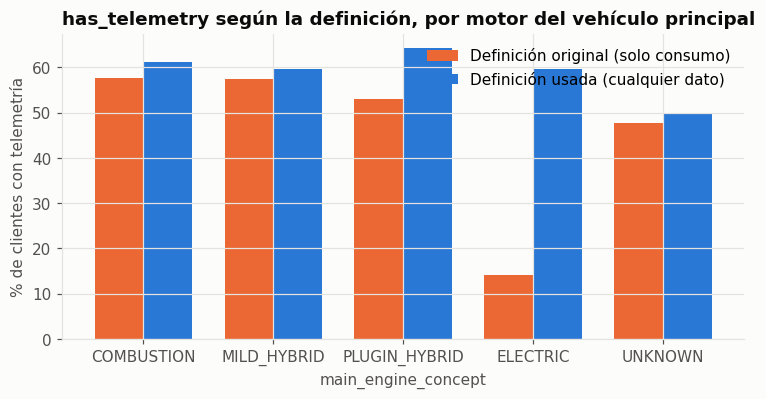

,Definición original (solo consumo),Definición usada (cualquier dato)
main_engine_concept,,
COMBUSTION,57.7,61.2
ELECTRIC,14.2,59.6
MILD_HYBRID,57.5,59.7
PLUGIN_HYBRID,53.0,64.2
UNKNOWN,47.8,49.8


In [21]:
def f_has_telemetry(c):
    return c["has_telemetry"].astype(int)       # agregado en B a partir de has_telemetry_row (A.9)

clientes["has_telemetry"] = f_has_telemetry(clientes)
solo_consumo = df.groupby("client_id").has_consumption_data.max().reindex(clientes.index).astype(int)
t = pd.DataFrame({"Definición original (solo consumo)": solo_consumo.groupby(clientes.main_engine_concept).mean(),
                  "Definición usada (cualquier dato)": clientes.has_telemetry.groupby(clientes.main_engine_concept).mean()}).mul(100)
ax = t.reindex(orden).plot.bar(figsize=(8, 3.6), color=[ps.SERIES[1], ps.SERIES[0]], width=0.75, rot=0)
ax.set_ylabel("% de clientes con telemetría"); ax.set_title("has_telemetry según la definición, por motor del vehículo principal")
plt.savefig(FIG_DIR / "02b_has_telemetry.png"); plt.show()
t.round(1)

### C.8 `urban_density_classification` · Personas por hogar de la zona

- **Qué mide (según el listado):** concentración urbana de la zona del cliente.
- **Columnas de origen:** `population` y `number_of_households` (tratadas en A.8).
- **Cálculo:** $\text{urban\_density\_classification} = \dfrac{\text{population}}{\text{number\_of\_households}}$ · **SQL:** `population / NULLIF(number_of_households, 0)`
- Se deja como **ratio numérico** (una de las dos opciones del listado), porque para clasificar en tramos *Rural / Urbano / Metropolitano*
  primero hay que comprobar que el ratio realmente mide urbanidad. Lo comprobamos:

In [22]:
def f_urban_density_classification(c):
    return c["population"] / c["number_of_households"].replace(0, np.nan)

clientes["urban_density_classification"] = f_urban_density_classification(clientes)
zonas = df[~df.socio_imputed].drop_duplicates(["country_code", "zipcode"])
zonas = zonas.assign(ratio=zonas.population / zonas.number_of_households,
                     tamano_zona=pd.qcut(zonas.population, 5, labels=["muy pequeña", "pequeña", "media", "grande", "muy grande"]))
print(f"Ratio por zona: mediana {zonas.ratio.median():.2f} · coef. de variación {zonas.ratio.std() / zonas.ratio.mean():.2f}")
print(f"Correlación (Spearman) entre el ratio y la población de la zona: {zonas[['ratio', 'population']].corr('spearman').iloc[0, 1]:.3f}")
zonas.groupby("tamano_zona", observed=True).ratio.median().round(2).to_frame("personas por hogar (mediana)")

Ratio por zona: mediana 2.31 · coef. de variación 0.10
Correlación (Spearman) entre el ratio y la población de la zona: 0.002


,personas por hogar (mediana)
tamano_zona,
muy pequeña,2.23
pequeña,2.34
media,2.36
grande,2.35
muy grande,2.25


**Resultado:** el ratio es en realidad el **tamaño medio del hogar** (≈ 2,3 personas), varía muy poco entre zonas y **no tiene relación
con el tamaño de la zona** (correlación ≈ 0): las zonas más pobladas no tienen hogares más pequeños. Para medir densidad haría falta la
**superficie** del código postal, que no tenemos.

**Decisión:** se calcula y se guarda en el CSV con el nombre acordado, documentando que mide *personas por hogar*, pero **no entra en el modelo**
(no aporta separación y su nombre sugiere algo que no mide). Tampoco se clasifica en tramos con etiquetas urbanas que no podríamos justificar.

### C.9 `digital_engagement_index` · Índice de conectividad multicanal

- **Qué mide:** afinidad del cliente con los vehículos conectados y los canales digitales.
- **Columnas de origen:** `currently_connected_vehicles` y `consent_epost_communication_channel`.
- **Cálculo:** $\text{digital\_engagement\_index} = \text{currently\_connected\_vehicles} + \mathbb{1}(\text{acepta e-post})$
- **SQL:** `currently_connected_vehicles + CASE WHEN consent_epost_communication_channel THEN 1 ELSE 0 END`
- **Por qué es útil:** prioriza a quién dirigir comunicaciones digitales y servicios de la app.
- **A tener en cuenta:** el 98 % acepta e-post, así que en la práctica el índice es casi "vehículos conectados + 1"; la diferencia la marca el 2 % que no lo acepta.

In [23]:
def f_digital_engagement_index(c):
    return c["currently_connected_vehicles"] + c["consent_epost_communication_channel"].astype(int)

clientes["digital_engagement_index"] = f_digital_engagement_index(clientes)
print(f"Aceptan e-post: {clientes.consent_epost_communication_channel.mean():.1%}")
clientes.digital_engagement_index.clip(upper=6).value_counts().sort_index().rename(index={6: "6+"}).to_frame("clientes")

Aceptan e-post: 98.3%


,clientes
digital_engagement_index,
0,381
1,19997
2,138752
3,11192
4,1574
5,534
6+,1026


### C.10 `main_is_van` · Vehículo comercial / furgoneta

- **Qué mide:** si el vehículo principal es un comercial ligero (furgoneta o pick-up).
- **Columnas de origen:** `product_group` del vehículo principal (comprobado contra `model_class`).
- **Cálculo:** 1 si `product_group = 'T'`, si no 0 · **SQL:** `CASE WHEN product_group = 'T' THEN 1 ELSE 0 END`
- **Ajuste:** el código de ejemplo usaba `product_group == 'V'`, pero **ese valor no existe** en los datos (hay `P`, `T`, `G`, `F`):
  daría 0 a todos los clientes. La tabla de abajo muestra que `T` agrupa exactamente las clases comerciales (Sprinter, Vito/V-Class, Citan, X-Class).
- **Por qué es útil:** separa el uso profesional / familiar de furgoneta del turismo particular.

In [24]:
def f_main_is_van(c):
    return c["main_product_group"].eq("T").astype(int)

clientes["main_is_van"] = f_main_is_van(clientes)
print("Valores de product_group:", raw.product_group.value_counts().to_dict())
print("Con la condición del código de ejemplo (== 'V'):", int((clientes.main_product_group == "V").sum()), "clientes")
display(pd.crosstab(df.model_class, df.product_group).loc[lambda t: t["T"] > 0, ["T"]])
print(f"main_is_van = 1: {clientes.main_is_van.mean():.1%} de los clientes")

Valores de product_group: {'P': 255604, 'T': 41937, 'G': 4373, 'F': 936}
Con la condición del código de ejemplo (== 'V'): 0 clientes


product_group,T
model_class,
Citan,3477
Sprinter,10466
V-Class / Vito,27350
Viano/Vito,202
X-Class,442


main_is_van = 1: 10.8% de los clientes


### C.11 Comprobación: el SQL da exactamente lo mismo que pandas

Ejecutamos con **DuckDB** una única consulta SQL que calcula todas las features derivadas desde la tabla de filas limpias, y la comparamos con lo calculado en pandas.

In [25]:
SQL_FEATURES = """
WITH ranked AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY client_id
              ORDER BY is_current_vehicle DESC, date_of_first_registration DESC, vehicle_id) AS rn
    FROM filas_limpias),
main AS (
    SELECT *, (DATE '2026-10-15' - CAST(date_of_first_registration AS DATE)) / 365.25 AS age
    FROM ranked WHERE rn = 1),
hist AS (
    SELECT client_id,
           COUNT(DISTINCT vehicle_id) AS n_vehicles_history,
           SUM(workshop_visits_warranty_goodwill) AS workshop_visits_total,
           MAX(CASE WHEN trip_distance_median IS NOT NULL OR speed_median IS NOT NULL
                     OR operating_hours_total IS NOT NULL OR fuel_consumption_average IS NOT NULL
                    THEN 1 ELSE 0 END) AS has_telemetry
    FROM filas_limpias GROUP BY client_id)
SELECT main.client_id,
       main.age                                                             AS main_vehicle_age_years,
       main.months_as_mb_customer / 12.0                                    AS tenure_years,
       CASE WHEN main.country_code = 'AT'
            THEN CASE WHEN main.age < 3 THEN 0 WHEN main.age < 5 THEN 1 ELSE 2 + FLOOR(main.age - 5) END
            ELSE CASE WHEN main.age < 5 THEN 0 WHEN main.age < 8 THEN 1 ELSE 2 + FLOOR((main.age - 8) / 2) END
       END                                                                  AS itvs_passed_count,
       hist.workshop_visits_total * 1.0 / hist.n_vehicles_history           AS warranty_visit_frequency,
       hist.has_telemetry                                                   AS has_telemetry,
       main.population / NULLIF(main.number_of_households, 0)               AS urban_density_classification,
       main.currently_connected_vehicles
         + CASE WHEN main.consent_epost_communication_channel THEN 1 ELSE 0 END AS digital_engagement_index,
       CASE WHEN main.product_group = 'T' THEN 1 ELSE 0 END                 AS main_is_van
FROM main JOIN hist ON main.client_id = hist.client_id
"""
filas_limpias = df
sql = duckdb.sql(SQL_FEATURES).df().set_index("client_id").sort_index()
DERIVED = ["main_vehicle_age_years", "tenure_years", "itvs_passed_count", "warranty_visit_frequency",
           "has_telemetry", "urban_density_classification", "digital_engagement_index", "main_is_van"]
check = pd.DataFrame({f: {"máx. diferencia SQL vs pandas": float(np.abs(sql[f].astype(float) - clientes[f].astype(float)).max())}
                      for f in DERIVED}).T
assert (check.iloc[:, 0] < 1e-9).all()
check

,máx. diferencia SQL vs pandas
main_vehicle_age_years,0.0
tenure_years,0.0
itvs_passed_count,0.0
warranty_visit_frequency,0.0
has_telemetry,0.0
urban_density_classification,0.0
digital_engagement_index,0.0
main_is_van,0.0


### C.12 Distribución de las features derivadas

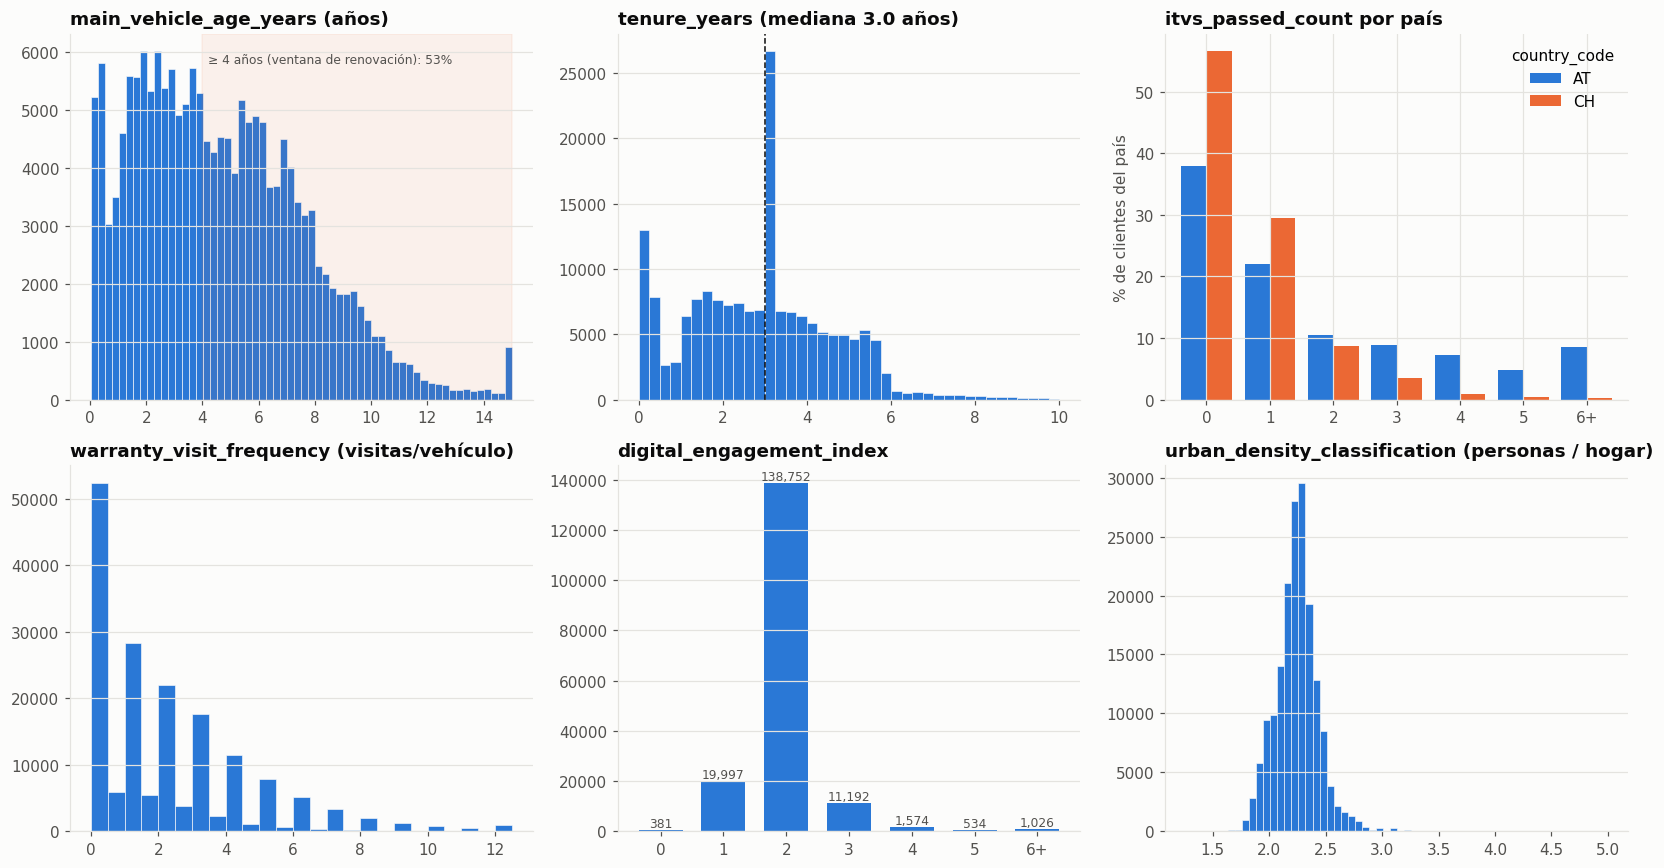

has_telemetry = 1: 60.0% · main_is_van = 1: 10.8%


In [26]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
ax = axes[0, 0]
s = clientes.main_vehicle_age_years
ax.hist(s.clip(upper=15), bins=60, color=ps.SERIES[0], edgecolor="#fcfcfb", lw=0.4)
ax.axvspan(4, 15, color=ps.SERIES[1], alpha=0.08)
ax.text(4.2, ax.get_ylim()[1] * 0.92, f"≥ 4 años (ventana de renovación): {(s >= 4).mean():.0%}", fontsize=8, color=ps.INK_2)
ax.set_title("main_vehicle_age_years (años)")
ax = axes[0, 1]
ax.hist(clientes.tenure_years, bins=40, color=ps.SERIES[0], edgecolor="#fcfcfb", lw=0.4)
ax.axvline(clientes.tenure_years.median(), color=ps.INK, ls="--", lw=1)
ax.set_title(f"tenure_years (mediana {clientes.tenure_years.median():.1f} años)")
ax = axes[0, 2]
it = pd.crosstab(clientes.itvs_passed_count.clip(upper=6), clientes.country_code, normalize="columns") * 100
it.plot.bar(ax=ax, color=[ps.SERIES[0], ps.SERIES[1]], width=0.8, rot=0)
ax.set_xticks(range(len(it)), [str(i) if i < 6 else "6+" for i in it.index]); ax.set_ylabel("% de clientes del país")
ax.set_title("itvs_passed_count por país"); ax.set_xlabel("")
ax = axes[1, 0]
ax.hist(clientes.warranty_visit_frequency.clip(upper=12), bins=np.arange(0, 12.51, 0.5), color=ps.SERIES[0], edgecolor="#fcfcfb", lw=0.4)
ax.set_title("warranty_visit_frequency (visitas/vehículo)")
ax = axes[1, 1]
v = clientes.digital_engagement_index.clip(upper=6).value_counts().sort_index()
ps.bar(ax, [str(i) if i < 6 else "6+" for i in v.index], v.values)
ax.set_title("digital_engagement_index")
ax = axes[1, 2]
ax.hist(clientes.urban_density_classification, bins=60, color=ps.SERIES[0], edgecolor="#fcfcfb", lw=0.4)
ax.set_title("urban_density_classification (personas / hogar)")
fig.tight_layout(); fig.savefig(FIG_DIR / "02b_features_derivadas.png"); plt.show()
print(f"has_telemetry = 1: {clientes.has_telemetry.mean():.1%} · main_is_van = 1: {clientes.main_is_van.mean():.1%}")

---
# D. Selección justificada de features para el modelo

No se usan todas las columnas: se eligen las que **diferencian clientes** de forma útil para marketing, tienen buena calidad y **no son redundantes**.
Comprobamos la redundancia con la correlación entre candidatas:

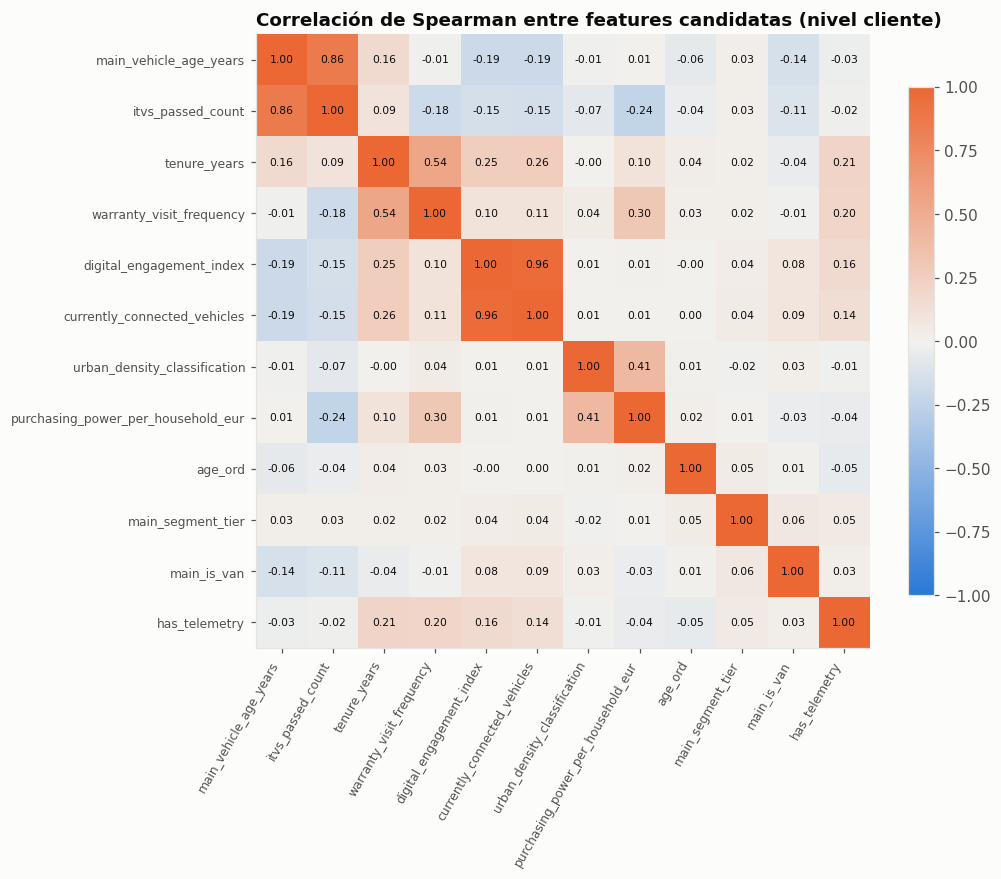

ρ(main_vehicle_age_years, itvs_passed_count) = 0.86
ρ(digital_engagement_index, currently_connected_vehicles) = 0.96


In [27]:
cand = clientes.assign(age_ord=clientes.age_range.map(mf.AGE_ORDER),
                       main_segment_tier=clientes.main_model_class.map(mf.SEGMENT_TIER))
cand_cols = ["main_vehicle_age_years", "itvs_passed_count", "tenure_years", "warranty_visit_frequency",
             "digital_engagement_index", "currently_connected_vehicles", "urban_density_classification",
             "purchasing_power_per_household_eur", "age_ord", "main_segment_tier", "main_is_van", "has_telemetry"]
c = cand[cand_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(c, cmap=ps.DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns, rotation=60, ha="right", fontsize=8); ax.set_yticks(range(len(c)), c.columns, fontsize=8)
ax.grid(False)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7, color=ps.INK)
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Correlación de Spearman entre features candidatas (nivel cliente)")
fig.savefig(FIG_DIR / "02b_correlaciones_candidatas.png"); plt.show()
print(f"ρ(main_vehicle_age_years, itvs_passed_count) = {c.loc['main_vehicle_age_years', 'itvs_passed_count']:.2f}")
print(f"ρ(digital_engagement_index, currently_connected_vehicles) = {c.loc['digital_engagement_index', 'currently_connected_vehicles']:.2f}")

### Features que entran en el modelo

| Feature | Tipo | Origen | Justificación |
|---|---|---|---|
| `main_vehicle_age_years` | numérica | derivada C.1 | Ventana de renovación → **ofertas de vehículo** |
| `tenure_years` | numérica | derivada C.2 | Lealtad y ciclo de vida → **fidelización** |
| `warranty_visit_frequency` | numérica | derivada C.4 | Uso de posventa → **planes de mantenimiento** |
| `digital_engagement_index` | numérica | derivada C.9 | Vehículos conectados + canal digital → **comunicaciones dirigidas** |
| `purchasing_power_per_household_eur` | numérica | base | Capacidad de compra de la zona → nivel de oferta |
| `age_range` | ordinal | base | Etapa vital; se codifica 0-5 respetando el orden |
| `main_model_class` → gama 1-4 | ordinal | base | Nivel de gama del vehículo (compacto … lujo) → upsell |
| `main_is_van` | binaria | derivada C.10 | Uso profesional / furgoneta |
| `has_telemetry` | binaria | derivada C.7 | Cliente conectado vs. tradicional |
| `finance_leasing_status` | nominal (4) | base | Relación con Mercedes-Benz Financial → momento de renovar el leasing |
| `main_engine_concept` | nominal (5, con `UNKNOWN`) | base tratada | Afinidad eléctrica / híbrida |

### Features que **no** entran (y por qué)

| Feature | Motivo |
|---|---|
| `itvs_passed_count` | Es una función escalonada de la antigüedad (ρ = 0,86 con `main_vehicle_age_years`): meterla duplicaría el peso de la edad del coche. Se guarda en el CSV para perfilar. |
| `currently_connected_vehicles` | Ya está dentro de `digital_engagement_index` (ρ = 0,96). |
| `urban_density_classification` | Mide personas por hogar, casi constante y sin relación con la urbanidad (C.8). |
| `country_code` | Partiría el modelo en CH/AT y taparía comportamientos comunes; su efecto económico ya está en el poder adquisitivo. Se usa para perfilar. |
| `gender_derived` | Inferido, con nulos no aleatorios: riesgo de sesgo (Parte 1). |
| Telemetría (métricas) | 60 % de falta estructural; sustituida por `has_telemetry` (Parte 1). |
| Identificadores y alta cardinalidad (`client_id`, `vehicle_id`, `zipcode`, `model_series`, `vehicle_type`) | Sin valor analítico (Parte 1). |
| Consentimientos teléfono / correo postal | Los aceptan ~85 %: casi no separan clientes. Se conservan en el CSV para elegir canal. |
| Resto de variables de zona | Redundantes con el poder adquisitivo por hogar o miden el tamaño de la zona, no del cliente. |

---
# E. Pipeline de transformación

Todo lo anterior se encapsula en un único `sklearn.Pipeline`. Cada paso es un transformador con `fit` (aprende de los datos) y `transform` (aplica):

1. **`TratamientoNulos`**: en `fit` aprende las tablas de consulta (motor, clase, combustible) y las medianas (serie, país, grupo); en `transform` las aplica (sección A).
2. **`AgregacionClientes`**: pasa a 1 fila por cliente (sección B).
3. **`FeaturesDerivadas`**: calcula las 8 features derivadas (sección C).
4. **`ColumnTransformer`**: codificación y escalado de las features seleccionadas (sección D):

| Grupo | Columnas | Tratamiento | Por qué |
|---|---|---|---|
| Numéricas con cola larga | `warranty_visit_frequency`, `digital_engagement_index`, `purchasing_power_per_household_eur` | mediana → `log1p` → `RobustScaler` | El log comprime la cola (clientes con 20 coches o 40 visitas) |
| Numéricas | `main_vehicle_age_years`, `tenure_years` | mediana → `RobustScaler` | — |
| Ordinal edad | `age_range` | `OrdinalEncoder` (<25 … 65+ = 0 … 5) → `RobustScaler` | Respeta el orden natural en 1 columna |
| Ordinal gama | `main_model_class` | clase → gama 1-4 → mediana (para `UNKNOWN`) → `RobustScaler` | 42 clases resumidas en un nivel de gama |
| Binarias | `main_is_van`, `has_telemetry` | se dejan en 0/1 | Escalar una binaria rara la haría dominar la distancia |
| Nominales | `finance_leasing_status`, `main_engine_concept` | `OneHotEncoder` | Sin orden natural; `UNKNOWN` es una categoría más |

**¿Por qué `RobustScaler`?** La Parte 1 detectó valores extremos y asimetrías. `RobustScaler` centra en la **mediana** y escala por el
**rango intercuartílico**, así que los outliers no deforman la escala del resto de clientes (con `StandardScaler`, media y desviación sí se ven arrastradas).

La imputación por mediana dentro del pipeline es una **red de seguridad**: tras la sección A ya no queda ningún nulo, pero si el pipeline
se aplica a datos nuevos (p. ej. una clase de coche que no está en el mapa de gamas) los rellenará en vez de fallar.

In [28]:
class TratamientoNulos(BaseEstimator, TransformerMixin):
    """Sección A: trata los nulos de cada columna según su naturaleza (fila cliente-vehículo)."""

    @staticmethod
    def _prep(X):
        d = X.drop(columns="Unnamed: 0", errors="ignore").copy()
        d["date_of_first_registration"] = pd.to_datetime(d["date_of_first_registration"], errors="coerce")
        d.loc[d.date_of_first_registration < "2000-01-01", "date_of_first_registration"] = pd.NaT
        d["reg_year"] = d.date_of_first_registration.dt.year
        d["vehicle_type"] = d.vehicle_type.fillna("UNKNOWN")
        d["type_prefix"] = d.vehicle_type.str.replace(r"^(?:MERCEDES-)?AMG\s+", "", regex=True).str.split().str[0]
        d.loc[d.population == 0, ["population", "number_of_households"]] = np.nan
        return d

    def fit(self, X, y=None):
        d = self._prep(X)
        self.mc_ = fit_cascade(d[d.model_class.notna()], "model_class", MC_LEVELS)
        d["model_class"], _ = apply_cascade(d, "model_class", [], self.mc_)
        self.engine_ = fit_cascade(d[d.engine_concept.notna()], "engine_concept", ENGINE_LEVELS)
        d["engine_concept"], _ = apply_cascade(d, "engine_concept", ENGINE_RULES, self.engine_)
        d = add_diesel_flag(d)
        self.fuel_ = fit_cascade(d[d.fuel_type.notna()], "fuel_type", FUEL_LEVELS)
        days = (d.date_of_first_registration - epoch).dt.days
        self.date_series_, self.date_global_ = days.groupby(d.model_series).median(), days.median()
        self.months_grp_ = d.groupby("currently_connected_vehicles").months_as_mb_customer.median()
        self.months_global_ = d.months_as_mb_customer.median()
        self.zone_med_ = d.groupby("country_code")[ZONE_COLS].median()
        return self

    def transform(self, X):
        d = self._prep(X)
        d["model_class"], _ = apply_cascade(d, "model_class", [], self.mc_)
        d["engine_concept_imputed"] = d.engine_concept.isna()
        d["engine_concept"], _ = apply_cascade(d, "engine_concept", ENGINE_RULES, self.engine_)
        d = add_diesel_flag(d)
        d["fuel_type"], _ = apply_cascade(d, "fuel_type", FUEL_RULES, self.fuel_)
        d["registration_date_imputed"] = d.date_of_first_registration.isna()
        days = (d.date_of_first_registration - epoch).dt.days
        days = days.fillna(d.model_series.map(self.date_series_)).fillna(self.date_global_)
        d["date_of_first_registration"] = epoch + pd.to_timedelta(days.round(), unit="D")
        d["gender_derived"] = d.gender_derived.fillna("UNKNOWN")
        d["months_as_mb_customer"] = (d.months_as_mb_customer.fillna(d.currently_connected_vehicles.map(self.months_grp_))
                                      .fillna(self.months_global_))
        d["socio_imputed"] = d.purchasing_power_per_household_eur.isna()
        for c in ZONE_COLS:
            d[c] = d[c].fillna(d.country_code.map(self.zone_med_[c]))
        d.loc[d.socio_imputed, "purchasing_power_millions_eur"] = (d.purchasing_power_per_inhabitant_eur * d.population / 1e6)[d.socio_imputed]
        d["zipcode"] = d.zipcode.fillna("UNKNOWN")
        for k, c in TEL_BLOCKS.items():
            d[f"has_{k}_data"] = d[c].notna()
        d["has_telemetry_row"] = d[[f"has_{k}_data" for k in TEL_BLOCKS]].any(axis=1)
        return d


class AgregacionClientes(BaseEstimator, TransformerMixin):
    """Sección B: 1 fila por cliente (vehículo principal + agregados del historial)."""
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        return agregar_clientes(X)


class FeaturesDerivadas(BaseEstimator, TransformerMixin):
    """Sección C: las 8 features derivadas calculables."""
    FUNCS = {"main_vehicle_age_years": f_main_vehicle_age_years, "tenure_years": f_tenure_years,
             "itvs_passed_count": f_itvs_passed_count, "warranty_visit_frequency": f_warranty_visit_frequency,
             "has_telemetry": f_has_telemetry, "urban_density_classification": f_urban_density_classification,
             "digital_engagement_index": f_digital_engagement_index, "main_is_van": f_main_is_van}
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        c = X.copy()
        for name, f in self.FUNCS.items():      # el orden importa: itvs usa la antigüedad
            c[name] = f(c)
        return c

In [29]:
LOG_FEATS = ["warranty_visit_frequency", "digital_engagement_index", "purchasing_power_per_household_eur"]
NUM_FEATS = ["main_vehicle_age_years", "tenure_years"]
BIN_FEATS = ["main_is_van", "has_telemetry"]
CAT_FEATS = ["finance_leasing_status", "main_engine_concept"]
AGE_CATS = ["<25", "25-34", "35-44", "45-54", "55-64", "65+"]

def class_to_tier(x):
    return pd.DataFrame(x).iloc[:, 0].map(mf.SEGMENT_TIER).to_frame("main_segment_tier")

def tier_names(transformer, input_features):
    return np.array(["main_segment_tier"])

preprocesado = ColumnTransformer([
    ("log_robust", Pipeline([("imputar", SimpleImputer(strategy="median")),
                             ("log1p", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
                             ("escalar", RobustScaler())]), LOG_FEATS),
    ("robust", Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", RobustScaler())]), NUM_FEATS),
    ("edad", Pipeline([("ordinal", OrdinalEncoder(categories=[AGE_CATS])), ("escalar", RobustScaler())]), ["age_range"]),
    ("gama", Pipeline([("clase_a_gama", FunctionTransformer(class_to_tier, feature_names_out=tier_names)),
                       ("imputar", SimpleImputer(strategy="median")), ("escalar", RobustScaler())]), ["main_model_class"]),
    ("binarias", "passthrough", BIN_FEATS),
    ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_FEATS),
], verbose_feature_names_out=False)

pipeline = Pipeline([
    ("tratamiento_nulos", TratamientoNulos()),
    ("agregacion_clientes", AgregacionClientes()),
    ("features_derivadas", FeaturesDerivadas()),
    ("preprocesado", preprocesado),
])
set_config(display="diagram")
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('tratamiento_nulos', ...), ('agregacion_clientes', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('log_robust', ...), ('robust', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the 

### Ejecución del pipeline sobre el CSV original

In [30]:
clientes_pipe = pipeline[:-1].fit_transform(raw)          # pasos 1-3: CSV de clientes
X = pipeline[-1].fit_transform(clientes_pipe)              # paso 4: matriz para K-Means
feature_names = pipeline[-1].get_feature_names_out()
X_df = pd.DataFrame(X, columns=feature_names, index=clientes_pipe.index)
print(f"Matriz del modelo: {X_df.shape[0]:,} clientes × {X_df.shape[1]} columnas · nulos: {int(np.isnan(X).sum())}")

# El pipeline reproduce exactamente lo calculado paso a paso en las secciones A-C
iguales = {col: bool((clientes_pipe[col].astype(str) == clientes[col].astype(str)).all())
           for col in clientes.columns}
print("Columnas idénticas entre el pipeline y el paso a paso:", sum(iguales.values()), "de", len(iguales))
assert all(iguales.values()), [k for k, v in iguales.items() if not v]

Matriz del modelo: 173,456 clientes × 18 columnas · nulos: 0


Columnas idénticas entre el pipeline y el paso a paso: 35 de 35


In [31]:
resumen_X = pd.DataFrame({"mediana": X_df.median(), "p1": X_df.quantile(.01), "p99": X_df.quantile(.99),
                          "mín": X_df.min(), "máx": X_df.max()}).round(2)
resumen_X

,mediana,p1,p99,mín,máx
warranty_visit_frequency,0.0,-0.66,1.07,-0.66,1.95
digital_engagement_index,0.0,-0.41,0.51,-1.10,2.04
purchasing_power_per_household_eur,0.0,-1.31,1.62,-1.57,2.24
main_vehicle_age_years,0.0,-0.92,2.03,-0.94,4.93
tenure_years,0.0,-1.24,1.90,-1.24,2.90
age_range,0.0,-1.50,1.00,-1.50,1.00
main_segment_tier,0.0,-1.00,2.00,-1.00,2.00
main_is_van,0.0,0.00,1.00,0.00,1.00
has_telemetry,1.0,0.00,1.00,0.00,1.00
finance_leasing_status_active_FL_and_CASH,0.0,0.00,1.00,0.00,1.00


Tras el escalado, las numéricas quedan centradas en 0 (la mediana) con la mayoría de los clientes en un rango de pocas unidades,
comparable al 0/1 de las binarias y one-hot: ninguna variable domina la distancia por su escala original.

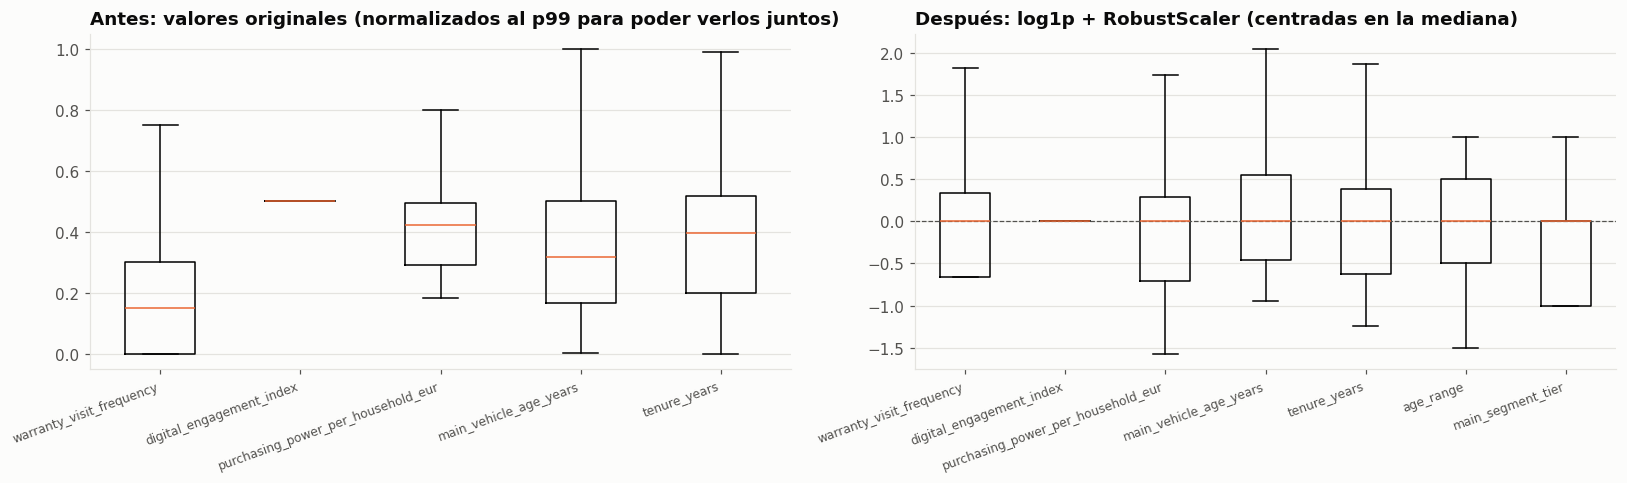

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
nums = LOG_FEATS + NUM_FEATS
antes = clientes_pipe[nums]
axes[0].boxplot([antes[c].clip(upper=antes[c].quantile(.99)) / antes[c].quantile(.99) for c in nums], showfliers=False)
axes[0].set_xticks(range(1, len(nums) + 1), nums, rotation=20, ha="right", fontsize=8)
axes[0].set_title("Antes: valores originales (normalizados al p99 para poder verlos juntos)")
axes[1].boxplot([X_df[c] for c in nums + ["age_range", "main_segment_tier"]], showfliers=False)
axes[1].set_xticks(range(1, len(nums) + 3), nums + ["age_range", "main_segment_tier"], rotation=20, ha="right", fontsize=8)
axes[1].axhline(0, color=ps.INK_2, lw=0.8, ls="--")
axes[1].set_title("Después: log1p + RobustScaler (centradas en la mediana)")
fig.tight_layout(); fig.savefig(FIG_DIR / "02b_escalado.png"); plt.show()

---
# F. Salidas: CSV de clientes y matriz del modelo

El CSV final contiene, por cliente: sus atributos con los nulos tratados, los del vehículo principal, los agregados del historial,
las **8 features derivadas** y los **indicadores** de imputación. Las columnas eliminadas en A.9 (telemetría, modas, contadores) y los
identificadores excluidos en la Parte 1 (`vehicle_id`, `zipcode`, `model_series`) no se incluyen.

In [33]:
out = clientes_pipe.reset_index()
out["main_date_of_first_registration"] = out.main_date_of_first_registration.dt.strftime("%Y-%m-%d")
assert out.isna().sum().sum() == 0, out.isna().sum()[lambda s: s > 0]
DATA_DIR.mkdir(exist_ok=True)
OUT_CSV = DATA_DIR / "clientes_features.csv"
out.to_csv(OUT_CSV, index=False)
X_df.to_pickle(DATA_DIR / "X_model_fe2.pkl")
chk = pd.read_csv(OUT_CSV, low_memory=False)
print(f"Guardado {OUT_CSV.name}: {chk.shape[0]:,} clientes × {chk.shape[1]} columnas · nulos: {int(chk.isna().sum().sum())}")
print(f"Guardada la matriz del modelo: X_model_fe2.pkl ({X_df.shape[1]} columnas)")
pd.DataFrame({"columna": out.columns, "tipo": out.dtypes.astype(str).values,
              "ejemplo": out.iloc[0].astype(str).str.slice(0, 30).values})

Guardado clientes_features.csv: 173,456 clientes × 36 columnas · nulos: 0
Guardada la matriz del modelo: X_model_fe2.pkl (18 columnas)


,columna,tipo,ejemplo
0,client_id,str,0000eb1785b60456d8ca6059563d61
1,age_range,str,55-64
2,gender_derived,str,male
3,country_code,str,AT
4,months_as_mb_customer,float64,46.0
5,currently_connected_vehicles,int64,1
6,finance_leasing_status,str,never_active
7,consent_phone_communication_channel,bool,True
8,consent_epost_communication_channel,bool,True
9,consent_post_communication_channel,bool,True


In [34]:
features_modelo = pd.DataFrame([
    ("main_vehicle_age_years", "derivada", "numérica · RobustScaler", "Ventana de renovación"),
    ("tenure_years", "derivada", "numérica · RobustScaler", "Lealtad y ciclo de vida"),
    ("warranty_visit_frequency", "derivada", "log1p · RobustScaler", "Uso de posventa"),
    ("digital_engagement_index", "derivada", "log1p · RobustScaler", "Conectividad y canal digital"),
    ("purchasing_power_per_household_eur", "base", "log1p · RobustScaler", "Capacidad de compra de la zona"),
    ("age_range", "base", "ordinal 0-5 · RobustScaler", "Etapa vital"),
    ("main_model_class", "base", "gama 1-4 · RobustScaler", "Nivel de gama"),
    ("main_is_van", "derivada", "binaria 0/1", "Uso profesional"),
    ("has_telemetry", "derivada", "binaria 0/1", "Cliente conectado"),
    ("finance_leasing_status", "base", "one-hot (4)", "Relación con la financiera"),
    ("main_engine_concept", "base tratada", "one-hot (5)", "Afinidad eléctrica"),
], columns=["feature", "origen", "codificación", "para qué sirve"])
features_modelo.to_csv(ROOT / "reports" / "fe2_features_modelo.csv", index=False)
features_modelo

,feature,origen,codificación,para qué sirve
0,main_vehicle_age_years,derivada,numérica · RobustScaler,Ventana de renovación
1,tenure_years,derivada,numérica · RobustScaler,Lealtad y ciclo de vida
2,warranty_visit_frequency,derivada,log1p · RobustScaler,Uso de posventa
3,digital_engagement_index,derivada,log1p · RobustScaler,Conectividad y canal digital
4,purchasing_power_per_household_eur,base,log1p · RobustScaler,Capacidad de compra de la zona
5,age_range,base,ordinal 0-5 · RobustScaler,Etapa vital
6,main_model_class,base,gama 1-4 · RobustScaler,Nivel de gama
7,main_is_van,derivada,binaria 0/1,Uso profesional
8,has_telemetry,derivada,binaria 0/1,Cliente conectado
9,finance_leasing_status,base,one-hot (4),Relación con la financiera


## Resumen

**Tratamiento de nulos (A):** cada columna según su naturaleza. Lo deducible se deduce con reglas **validadas** (motor, combustible, clase);
lo no deducible queda `UNKNOWN` (**nunca combustión por defecto**); lo numérico de contexto se imputa con la mediana de un grupo comparable y
se marca; la telemetría, con falta estructural, se convierte en `has_telemetry` y sus métricas se eliminan.

**Features derivadas (C):** 8 de las 10 acordadas, con su cálculo en pandas y en SQL (comprobados iguales con DuckDB):

| Feature | Columnas de origen | Ajuste |
|---|---|---|
| `main_vehicle_age_years` | `date_of_first_registration` | — |
| `tenure_years` | `months_as_mb_customer` | — |
| `itvs_passed_count` | antigüedad + `country_code` | Calendario de Austria (3-2-1) y Suiza (5-3-2), no el español |
| `warranty_visit_frequency` | `workshop_visits_warranty_goodwill`, `vehicle_id` | Dividido por vehículos del historial |
| `has_telemetry` | bloques de telemetría | Cualquier bloque (no solo consumo, que excluía a los eléctricos) |
| `urban_density_classification` | `population`, `number_of_households` | Mide personas por hogar; fuera del modelo |
| `digital_engagement_index` | `currently_connected_vehicles`, `consent_epost_communication_channel` | — |
| `main_is_van` | `product_group` | `'T'` en lugar de `'V'` (que no existe) |
| ~~`days_since_last_workshop_visit`~~ | — | **No calculable**: no hay fechas de taller |
| ~~`post_warranty_retention_flag`~~ | — | **No calculable**: solo hay visitas en garantía y sin fecha |

**Selección (D) y pipeline (E):** 11 features (6 derivadas + 5 base) → 18 columnas tras la codificación, en un único `Pipeline` reproducible.

**Salidas (F):** `data/clientes_features.csv` (1 fila por cliente, 0 nulos) y `data/X_model_fe2.pkl` (matriz lista para K-Means).
Ninguna se sube al repositorio (datos reales de clientes).